In [ ]:
## Analyse GenMoL properties

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import AllChem
import seaborn as sns
import scipy.stats  

## Data

In [2]:
## first Bayer Seed
#m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
#m1_name = "BCS-CN20332" 

## second seed
#m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
#m2_name = "BCS-CE65417"

# Replace with your seed SMILES
seed_smiles = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"


In [3]:
# READ GT
#df1 = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
df1 = pd.read_csv("/home/ec2-user/SageMaker/data/raw/input-mol-inference2/df_ICA_bionemo_eval_20250313.csv", sep="\t")
print(df1.shape)
df1.head(5)

(34471, 13)


,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-CT88194,['BCS-CT88194'],C#CCNC(=O)CNC(=O)c1cccc(C2=NOC(C)(C(=O)Nc3cc(C...,NaN,NaN,NaN,NaN,NaN,NaN,3.05,3.20,0.29,NaN
1,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN
2,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN
3,BCS-CT91305,['BCS-CT91305'],O=C(CNC(=O)c1ccc(C2=NOC(C(=O)Nc3ccccc3)C2)cc1)...,NaN,NaN,NaN,NaN,NaN,NaN,2.89,3.06,0.35,NaN
4,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN


In [4]:
# Base Generation
df2 = pd.read_csv("/home/ec2-user/SageMaker/data/interim/genmol/BCS-CE65417_R1_testmulti.csv")
print(df2.shape)
df2.head(2)

(236, 2)


,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835


In [5]:
# READ MOO
df3 = pd.read_csv("/home/ec2-user/SageMaker/data/processed/genmol/BCS-CE65417_moo-w-qsar.csv")
print(df3.shape)
df3.head(2)

(446, 3)


,Unnamed: 0,smiles,score
0,0,CCn1cc(CNC2=NOC(OC(=O)NCc3cccc(F)c3)C2)c(C)n1,0.789940
1,1,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,0.784192


In [ ]:
data/raw/Marvin_sample_by_prop_from_leads_20250307_c.csv
# READ MOO
df3 = pd.read_csv("/home/ec2-user/SageMaker/data/raw/Marvin_sample_by_prop_from_leads_20250307_c.csv")
print(df3.shape)
df3.head(2)

## Add descriptors

In [20]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors


# Function to calculate LogP
def calculate_logp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        return Descriptors.MolLogP(mol)
    else:
        return None

# Function to calculate Molecular Weight
def calculate_molecular_weight(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        return Descriptors.MolWt(mol)
    else:
        return None  # Return None if the SMILES is invalid

# Apply the function to the SMILES column and create a new LogP column
df2['LogP'] = df2['smiles'].apply(calculate_logp)
df1['LogP'] = df1['std_smiles'].apply(calculate_logp)
df3['LogP'] = df3['smiles'].apply(calculate_logp)
# Apply the functions to the SMILES column and create new columns
df2['MW'] = df2['smiles'].apply(calculate_molecular_weight)
df1['MW'] = df1['std_smiles'].apply(calculate_molecular_weight)
df3['MW'] = df3['smiles'].apply(calculate_molecular_weight)

In [21]:
from by_scorer_new import MoleculeScorer
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=True,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=False,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)
#df1['AIH'] = scorer2.get_qsar_aih_predictions(df1['smiles'])
#df1['HSEC'] = scorer2.get_qsar_hsec_predictions(df1['smiles'])
#df2['AIH'] = scorer2.get_qsar_aih_predictions(df2['valid_smiles'])
#df2['HSEC'] = scorer2.get_qsar_hsec_predictions(df2['valid_smiles'])

In [22]:
# DF1 is already scored by Joerg - just rename
df1.rename(columns={"AI_H": "AIH"}, inplace=True)
df1.head(2)

In [24]:
results2 = scorer.score(df2['smiles'])
df2['AIH'] = results2.qsar_aih_scores
df2['HSEC'] = results2.qsar_hsec_scores
df2.sort_values(by="AIH", ascending=False)
df2.head(2)

#~now scoring~#
#~Done scoring~#


In [27]:
results3 = scorer.score(df3['smiles'])
df3['AIH'] = results3.qsar_aih_scores
df3['HSEC'] = results3.qsar_hsec_scores
df3.sort_values(by="AIH", ascending=False)
df3.head(2)

#~now scoring~#
#~Done scoring~#


,Unnamed: 0,smiles,score,LogP,MW,AIH,HSEC
3,3,CCn1cc(CNC(=O)c2cc(Cl)cc(Cl)c2)c(C)n1,0.751049,3.44822,312.200,125.88,82.48
8,8,Cc1nn(C2CCO2)cc1CNc1ccc(Br)cc1,0.709528,3.48502,322.206,104.49,84.64


## Sort for later Top@K analysis

In [29]:
df1.sort_values(by="AIH", ascending=False, inplace=True)
df2.sort_values(by="AIH", ascending=False, inplace=True)
df3.sort_values(by="AIH", ascending=False, inplace=True)

## Analysis 

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def create_comparison_boxplots(df1, df2, columns=['LogP', 'MW', 'AIH', 'HSEC'], name1='Dataset 1', name2='Dataset 2'):
    # Set figure size and style
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(8, 6))  # Adjusted size for better visibility
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#86ce28']
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column}', fontweight='bold')
        axes[i].set_xlabel('')  # Remove x-axis label
        axes[i].grid(True, linestyle='--', alpha=0.7)
    
    # Add a legend outside the plots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, [name1, name2], loc='upper right', title='Datasets', fontsize='medium')
    
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for the legend
    plt.show()


<Figure size 1000x600 with 0 Axes>

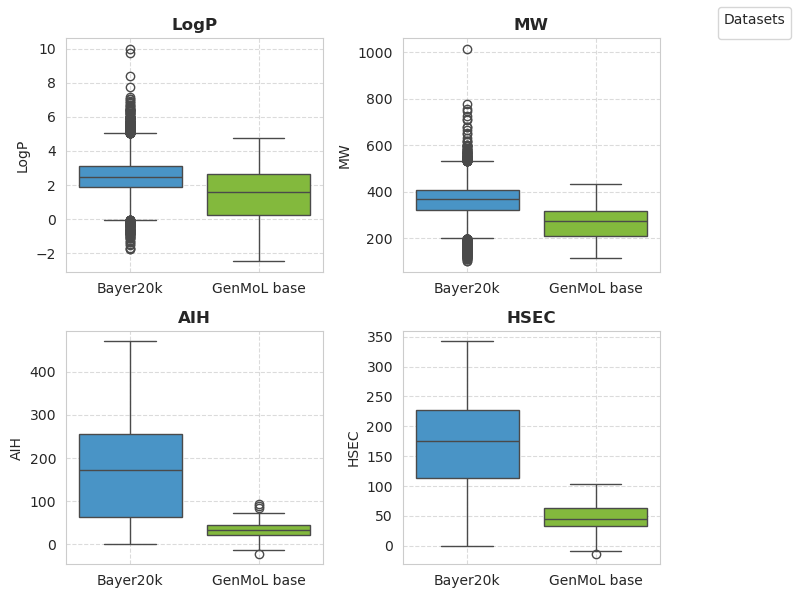

In [32]:

# Example usage
create_comparison_boxplots(df1, df2, name1="Bayer20k", name2="GenMoL base")

<Figure size 1000x600 with 0 Axes>

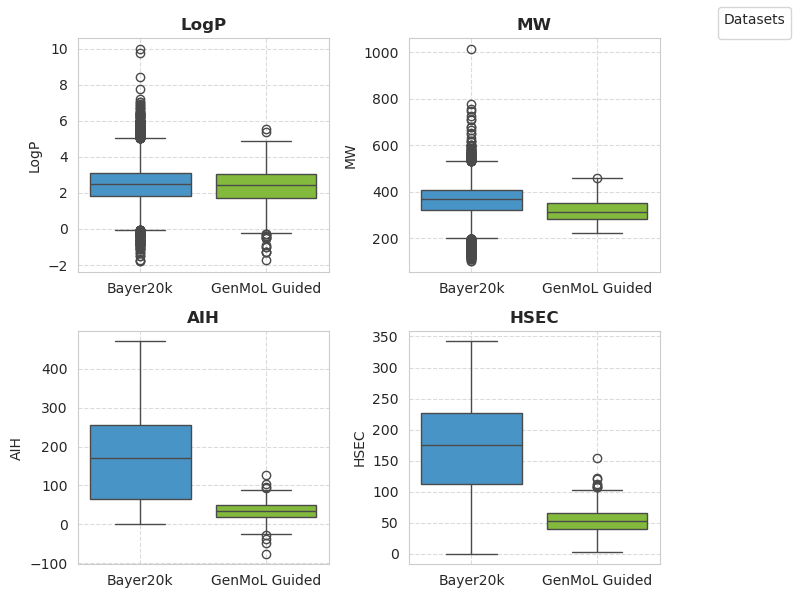

In [33]:
# Example usage
create_comparison_boxplots(df1, df3, name1="Bayer20k", name2="GenMoL Guided")

### ANALYSE TopK (K=10)

In [1]:
# Example usage
create_comparison_boxplots(df1[:100], df3[:100], name1="Bayer20k", name2="GenMoL Base")

NameError: name 'create_comparison_boxplots' is not defined

<Figure size 1000x600 with 0 Axes>

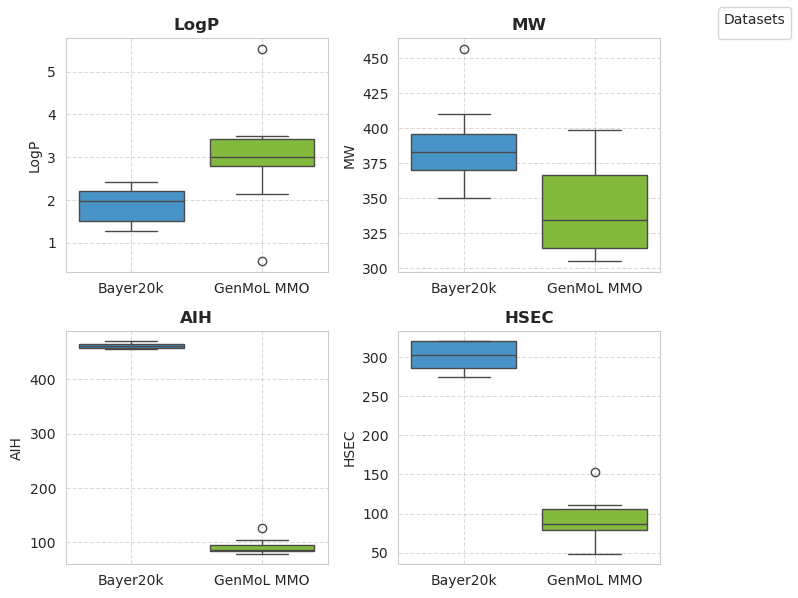

In [64]:
# Example usage
create_comparison_boxplots(df1[:10], df2[:10], name1="Bayer20k", name2="GenMoL MMO")

# compare all three

In [36]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def create_comparison_boxplots3(df1, df2, df3, columns=['LogP', 'MW', 'AIH', 'HSEC'], name1='Dataset 1', name2='Dataset 2', name3='Dataset 3'):
    # Set figure size and style
    plt.figure(figsize=(10, 6))
    sns.set_style("whitegrid")
    
    # Create subplots - one for each column
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))  # Adjusted size for better visibility
    axes = axes.flatten()
    
    # Define colors for each dataframe
    colors = ['#3498db', '#86ce28', '#e74c3c']  # Added a color for the third dataframe
    
    # Create boxplots for each column
    for i, column in enumerate(columns):
        # Create a temporary dataframe for plotting
        temp_df = pd.DataFrame({
            name1: df1[column],
            name2: df2[column],
            name3: df3[column]
        })
        
        # Melt the dataframe for seaborn
        melted_df = pd.melt(temp_df, var_name='Dataset', value_name=column)
        
        # Create boxplot (using hue instead of palette to avoid FutureWarning)
        sns.boxplot(x='Dataset', y=column, hue='Dataset', data=melted_df, palette=colors, ax=axes[i])
        
        # Set title and style
        axes[i].set_title(f'{column}', fontweight='bold')
        axes[i].set_xlabel('')  # Remove x-axis label
        axes[i].grid(True, linestyle='--', alpha=0.7)
    
    # Add a legend outside the plots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, [name1, name2, name3], loc='upper right', title='Datasets', fontsize='medium')
    
    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make space for the legend
    plt.show()


<Figure size 1000x600 with 0 Axes>

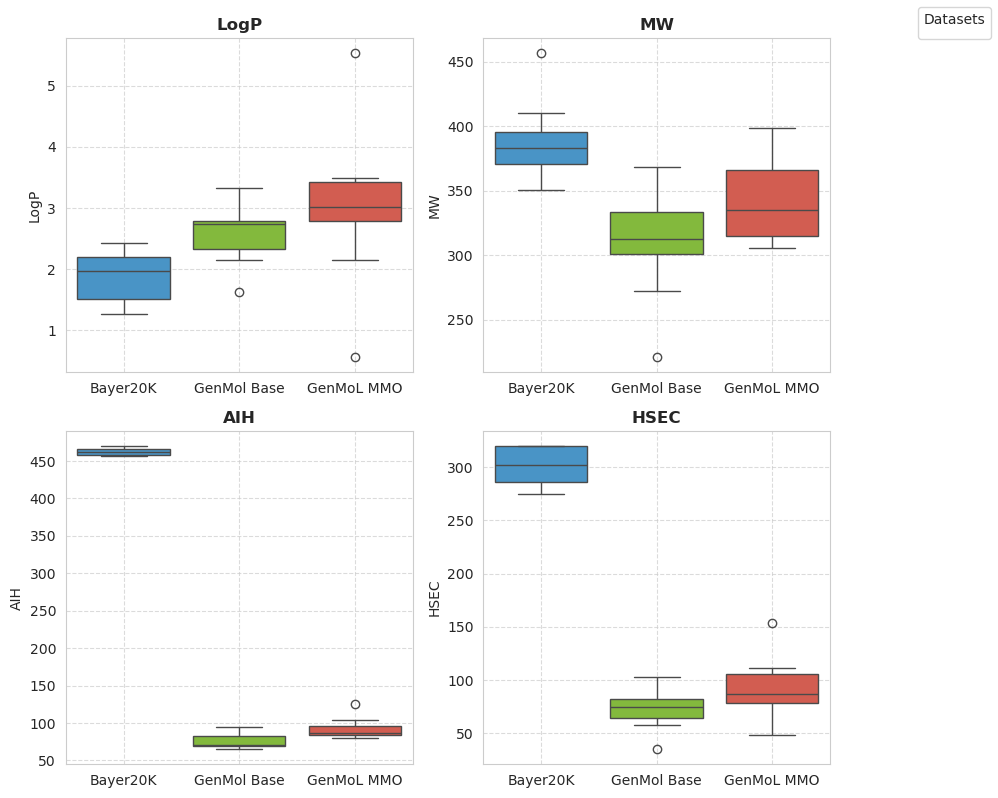

In [39]:
create_comparison_boxplots3(df1[:10], df2[:10], df3[:10], name1="Bayer20K", name2="GenMol Base", name3="GenMoL MMO")